# F2 · FLIR ADAS v2 dataset statistics

Visual summary of the report written by `projects/data_stats/stats.py`
(spec `spec/2026-10-08-flir-readers-class-mapping`, results note `stats.md`).

The notebook only **reads** `flir_stats.json` from a stats run dir under
`$IRWM_OUTPUT_ROOT/data_stats/<date>/<time>/`. By default it picks the most recent run;
set `RUN_DIR` to pin one. Setup: `uv sync --group notebook`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from irwm.data.classes import CLASS_NAMES
from irwm.utils.paths import load_env, output_root

load_env()

RUN_DIR: Path | None = None  # e.g. output_root() / "data_stats/2026-10-09/13-25-56"

if RUN_DIR is None:
    runs = sorted((output_root() / "data_stats").glob("*/*/flir_stats.json"))
    assert runs, f"no flir_stats.json under {output_root() / 'data_stats'}; run projects/data_stats/stats.py"
    RUN_DIR = runs[-1].parent
stats = json.loads((RUN_DIR / "flir_stats.json").read_text())
print(f"run dir: {RUN_DIR}")
print(f"commit:  {stats['git']['commit']}  dirty={stats['git']['dirty']}")
print(f"root:    {stats['config']['flir']['root']}")

run dir: /home/leonardo.ulloa/irwm/outputs/data_stats/2026-10-09/13-27-02
commit:  a4d65ef0724e29ee8a9fa2318fb56831df8e22b4  dirty=False
root:    /home/leonardo.ulloa/projects/data/teledyne_flir_adas_v2


In [2]:
# Plot style: two series (RGB, thermal) in fixed categorical slots 1-2; ignored classes in gray.
MOD_COLOR = {"rgb": "#2a78d6", "thermal": "#eb6834"}
MOD_LABEL = {"rgb": "RGB", "thermal": "Thermal"}
IGNORE_GRAY = "#a3a29c"
SPLITS = ["train", "val", "test"]
MODS = ["rgb", "thermal"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def table(header, rows):
    fmt = lambda v: f"{v:.2f}" if isinstance(v, float) else ("–" if v is None else str(v))
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


classes = stats["classes"]
row = {(c["name"], c["modality"], c["split"]): c for c in classes}
raw_names = sorted({c["name"] for c in classes},
                   key=lambda n: -sum(row[(n, m, s)]["boxes"] for m in MODS for s in SPLITS))

## 1. Images per split
Frames, frames without any annotation, and frames without any of the 6 kept classes.

In [3]:
table(["split", "images", "no annotation", "no kept box"],
      [[k, v["n_images"], v["no_annotation"], v["no_kept_box"]] for k, v in stats["images"].items()])
table(["split", "frame sizes (W×H: n)"],
      [[k, ", ".join(f"{s}: {n}" for s, n in v["sizes"].items())] for k, v in stats["images"].items()])

| split | images | no annotation | no kept box |
|---|---|---|---|
| rgb/train | 10318 | 265 | 280 |
| rgb/val | 1085 | 16 | 16 |
| rgb/test | 3749 | 0 | 98 |
| thermal/train | 10742 | 264 | 280 |
| thermal/val | 1144 | 16 | 19 |
| thermal/test | 3749 | 256 | 256 |

| split | frame sizes (W×H: n) |
|---|---|
| rgb/train | 1800x1600: 5015, 1224x1024: 1992, 2048x1536: 1886, 1280x1024: 1378, 720x480: 47 |
| rgb/val | 1800x1600: 879, 1224x1024: 183, 1280x1024: 23 |
| rgb/test | 1224x1024: 2151, 1024x768: 1598 |
| thermal/train | 640x512: 10742 |
| thermal/val | 640x512: 1144 |
| thermal/test | 640x512: 3749 |

## 2. All 16 raw FLIR classes — the imbalance study
Box counts on a log scale, summed over train + val + test. The 6 selected classes are
colored; the 10 ignored classes (ignore regions in training and evaluation) are gray.

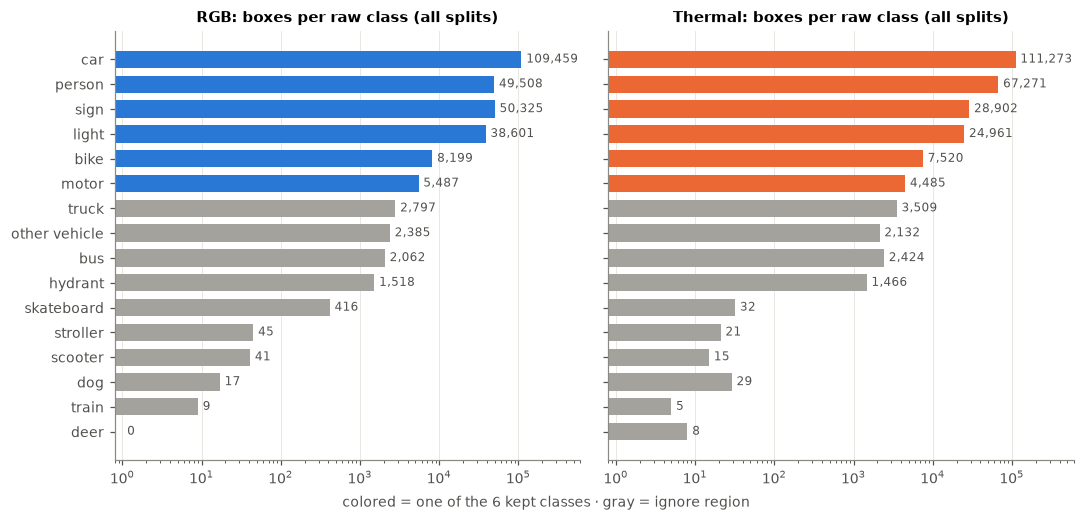

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
y = np.arange(len(raw_names))[::-1]
for ax, m in zip(axes, MODS):
    totals = [sum(row[(n, m, s)]["boxes"] for s in SPLITS) for n in raw_names]
    colors = [MOD_COLOR[m] if row[(n, m, "train")]["selected"] else IGNORE_GRAY for n in raw_names]
    ax.barh(y, [max(t, 0.8) for t in totals], height=0.7, color=colors)
    for yi, t in zip(y, totals):
        ax.text(max(t, 1) * 1.15, yi, f"{t:,}", va="center", fontsize=8, color="#52514e")
    ax.set_xscale("log")
    ax.set_xlim(0.8, 6e5)
    ax.set_title(f"{MOD_LABEL[m]}: boxes per raw class (all splits)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, raw_names)
fig.text(0.5, -0.01, "colored = one of the 6 kept classes · gray = ignore region", ha="center", color="#52514e")
fig.tight_layout()

In [5]:
flag_rows = []
for n in raw_names:
    r = row[(n, "rgb", "train")]
    flag_rows.append([n, r["category_id"], "yes" if r["selected"] else "", "yes" if r["coco80"] else "",
                      "yes" if r["absent_val"] or row[(n, "thermal", "val")]["absent_val"] else "",
                      "yes" if r["absent_test"] or row[(n, "thermal", "test")]["absent_test"] else "",
                      ", ".join(f"{m}/{s}" for m in MODS for s in SPLITS if row[(n, m, s)]["underrepresented"])])
table(["class", "FLIR id", "selected", "in COCO-80", "absent in val (any mod.)",
       "absent in test (any mod.)", "under-represented in"], flag_rows)

| class | FLIR id | selected | in COCO-80 | absent in val (any mod.) | absent in test (any mod.) | under-represented in |
|---|---|---|---|---|---|---|
| car | 3 | yes | yes |  |  |  |
| person | 1 | yes | yes |  |  |  |
| sign | 12 | yes |  |  |  |  |
| light | 10 | yes | yes |  |  |  |
| bike | 2 | yes | yes |  |  | rgb/test, thermal/test |
| motor | 4 | yes | yes |  |  | rgb/val, thermal/train, thermal/val |
| truck | 8 |  | yes |  |  | rgb/train, rgb/val, thermal/train, thermal/val |
| other vehicle | 79 |  |  |  |  | rgb/train, rgb/val, thermal/train, thermal/val |
| bus | 6 |  | yes |  | yes | rgb/test, thermal/test |
| hydrant | 11 |  | yes |  |  | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| skateboard | 37 |  | yes |  | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| stroller | 73 |  |  |  | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| scooter | 75 |  |  | yes | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| dog | 17 |  | yes | yes |  | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| train | 7 |  | yes | yes | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| deer | 18 |  |  | yes | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |

## 3. The 6 kept classes, per split
Kept boxes per class and split. Each panel has its own scale: train is ~10× val.

| class | RGB train | RGB val | RGB test | Thermal train | Thermal val | Thermal test |
|---|---|---|---|---|---|---|
| person | 35007 | 3223 | 11278 | 50478 | 4470 | 12323 |
| bike | 7560 | 193 | 446 | 7237 | 170 | 113 |
| car | 71281 | 7285 | 30893 | 73623 | 7133 | 30517 |
| motor | 1837 | 77 | 3573 | 1116 | 55 | 3314 |
| light | 18640 | 2143 | 17818 | 16198 | 2005 | 6758 |
| sign | 29531 | 3581 | 17213 | 20770 | 2472 | 5660 |
| **ignore (total)** | 5318 | 407 | 3565 | 5618 | 391 | 3632 |

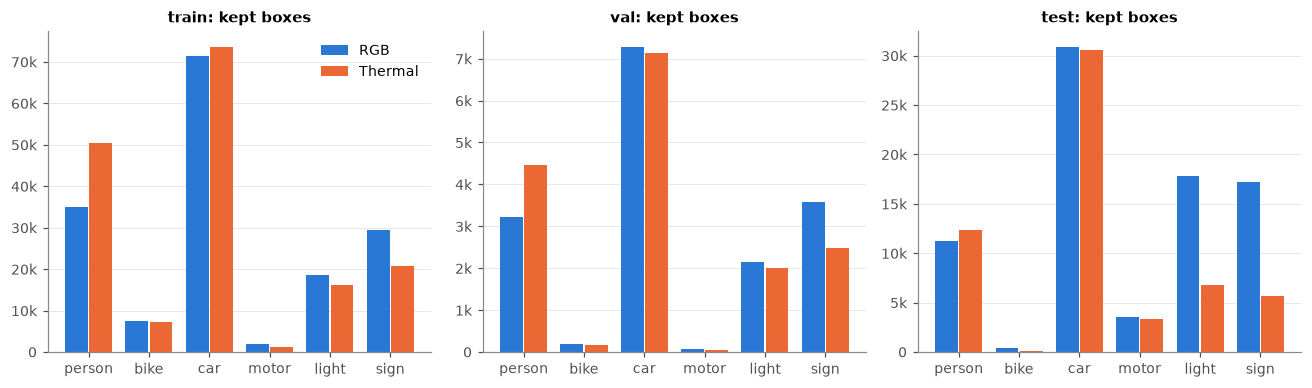

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
x = np.arange(len(CLASS_NAMES))
w = 0.38
for ax, s in zip(axes, SPLITS):
    for i, m in enumerate(MODS):
        vals = [stats["selected"][f"{m}/{s}"]["kept"][c] for c in CLASS_NAMES]
        # 2px-ish gap between the paired bars
        ax.bar(x + (i - 0.5) * (w + 0.02), vals, width=w, color=MOD_COLOR[m], label=MOD_LABEL[m])
    ax.set_xticks(x, CLASS_NAMES)
    ax.set_title(f"{s}: kept boxes")
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:g}k" if v >= 1000 else f"{v:g}"))
axes[0].legend(loc="upper right")
fig.tight_layout()

table(["class", *[f"{MOD_LABEL[m]} {s}" for m in MODS for s in SPLITS]],
      [[c, *[stats["selected"][f"{m}/{s}"]["kept"][c] for m in MODS for s in SPLITS]] for c in CLASS_NAMES]
      + [["**ignore (total)**", *[stats["selected"][f"{m}/{s}"]["total_ignore"] for m in MODS for s in SPLITS]]])

## 4. Modality asymmetry on the test split
Thermal ÷ RGB box count per kept class. The test frames are time-synced pairs, so a ratio
far from 1 means the two modalities were annotated differently, not that the scenes differ.

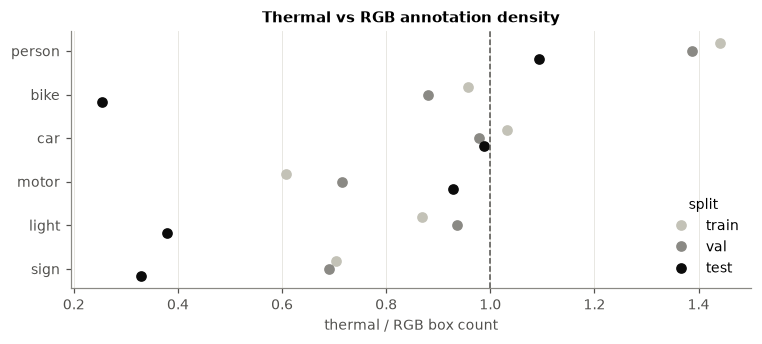

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
comp = stats["modality_comparison"]
for j, s in enumerate(SPLITS):
    vals = [comp[c][s] for c in CLASS_NAMES]
    ax.plot(vals, np.arange(len(CLASS_NAMES))[::-1] + (1 - j) * 0.18, "o", ms=6,
            color=["#c3c2b7", "#8a8984", "#0b0b0b"][j], label=s)
ax.axvline(1, color="#52514e", lw=1, ls="--")
ax.set_yticks(np.arange(len(CLASS_NAMES))[::-1], CLASS_NAMES)
ax.set_xlabel("thermal / RGB box count")
ax.set_title("Thermal vs RGB annotation density")
ax.legend(loc="lower right", title="split")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## 5. Object sizes (normalised to 640×512)
Share of kept boxes in the COCO buckets S (< 32²), M (< 96²) and L, after rescaling every
area to a 640×512 frame. Most objects are small, which matters for detection on a 14-px
patch grid (Roadmap R3).

| modality/split | S | M | L |
|---|---|---|---|
| rgb/train | 125708 | 32608 | 5540 |
| rgb/val | 13499 | 2476 | 527 |
| rgb/test | 72480 | 7100 | 1641 |
| thermal/train | 126045 | 36650 | 6727 |
| thermal/val | 12218 | 3395 | 692 |
| thermal/test | 50312 | 7162 | 1211 |

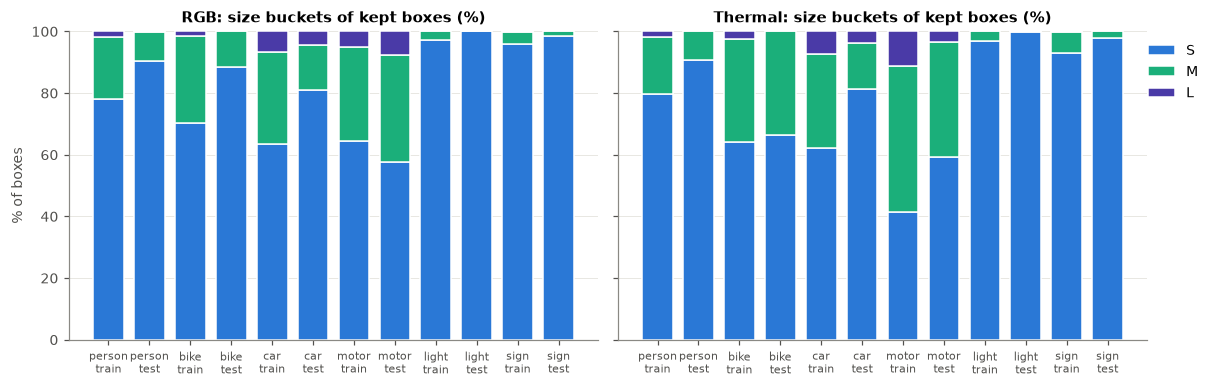

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
bucket_color = {"S": "#2a78d6", "M": "#1baf7a", "L": "#4a3aa7"}
for ax, m in zip(axes, MODS):
    labels, frac = [], {b: [] for b in "SML"}
    for c in CLASS_NAMES:
        for s in ("train", "test"):
            d = row[(c, m, s)]["size_normalised"]
            tot = sum(d.values()) or 1
            labels.append(f"{c}\n{s}")
            for b in "SML":
                frac[b].append(100 * d[b] / tot)
    xx = np.arange(len(labels))
    bottom = np.zeros(len(labels))
    for b in "SML":
        ax.bar(xx, frac[b], bottom=bottom, width=0.75, color=bucket_color[b], label=b,
               edgecolor="white", linewidth=1)
        bottom += frac[b]
    ax.set_xticks(xx, labels, fontsize=7)
    ax.set_title(f"{MOD_LABEL[m]}: size buckets of kept boxes (%)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of boxes")
axes[1].legend(loc="upper right", bbox_to_anchor=(1.12, 1))
fig.tight_layout()

table(["modality/split", "S", "M", "L"],
      [[f"{m}/{s}", *[sum(row[(c, m, s)]["size_normalised"][b] for c in CLASS_NAMES) for b in "SML"]]
       for m in MODS for s in SPLITS])

## 6. Test video sequences
Each bar is one contiguous run of frames on the `frame_index` axis; white space between runs
is a gap. These are the 8 sequences per modality that F3 cuts into clips.

| modality | video_id | frames | min | max | gaps (sizes) | tags |
|---|---|---|---|---|---|---|
| rgb | BzZspxAweF8AnKhWK | 338 | 745 | 1082 | – | fog, night, residential |
| rgb | FkqCGijjAKpABetZZ | 226 | 0 | 225 | – |  |
| rgb | PGdt7pJChnKoJDt35 | 208 | 368 | 575 | – | fog, night, residential |
| rgb | RMxN6a4CcCeLGu4tA | 1033 | 0 | 1479 | 271, 178 |  |
| rgb | YnfPeH8i2uBWmsSd2 | 540 | 300 | 839 | – | night, rain |
| rgb | dvZBYnphN2BwdMKBc | 565 | 0 | 564 | – |  |
| rgb | hnbGXq3nNPjBbc7CL | 411 | 99 | 509 | – | rain, night |
| rgb | msNEBxJE5PPDqenBM | 428 | 6393 | 8072 | 1253 |  |
| thermal | 4FRnNpmSmwktFJKjg | 338 | 745 | 1082 | – | fog, night, residential |
| thermal | 5RSrbWYu9eokv5bvR | 411 | 99 | 509 | – | night, rain |
| thermal | 6tLtjdkv5K5BuhB37 | 226 | 0 | 225 | – |  |
| thermal | SCiKdG3MqZfiE292B | 428 | 6393 | 8072 | 1253 | day |
| thermal | ZAtDSNuZZjkZFvMAo | 1033 | 0 | 1479 | 271, 178 |  |
| thermal | ePoikf5LyTTfqchga | 540 | 300 | 839 | – | rain, night |
| thermal | t3f7QC8hZr6zYXpEZ | 565 | 0 | 564 | – |  |
| thermal | vbrSzr4vFTm5QwuGH | 208 | 368 | 575 | – | fog, night, residential |

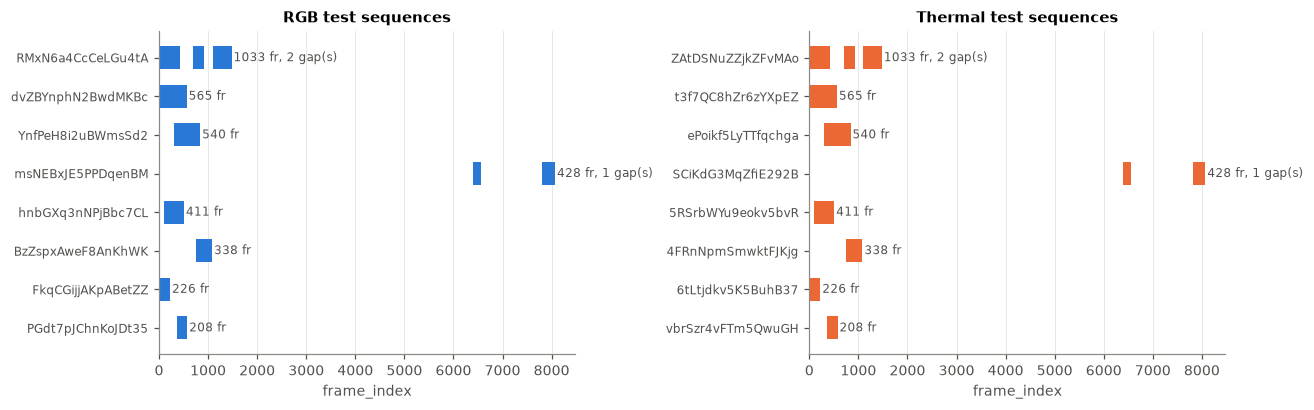

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m in zip(axes, MODS):
    seqs = sorted(stats["sequences"][m], key=lambda q: -q["n_frames"])
    for yi, q in enumerate(seqs):
        start = q["frame_min"]
        for seg, gap in zip(q["segments"], q["gap_sizes"] + [0]):
            ax.barh(yi, seg, left=start, height=0.6, color=MOD_COLOR[m])
            start += seg - 1 + gap
        ax.text(q["frame_max"] + 40, yi, f"{q['n_frames']} fr" + (f", {q['n_gaps']} gap(s)" if q["n_gaps"] else ""),
                va="center", fontsize=8, color="#52514e")
    ax.set_yticks(range(len(seqs)), [q["video_id"] for q in seqs], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("frame_index")
    ax.set_title(f"{MOD_LABEL[m]} test sequences")
    ax.grid(axis="y", visible=False)
fig.tight_layout()

table(["modality", "video_id", "frames", "min", "max", "gaps (sizes)", "tags"],
      [[m, q["video_id"], q["n_frames"], q["frame_min"], q["frame_max"],
        ", ".join(map(str, q["gap_sizes"])) or "–",
        ", ".join(t for t in q["tags"] if t in {"day", "night", "fog", "rain", "city", "highway", "residential"})]
       for m in MODS for q in stats["sequences"][m]])

## 7. File integrity
Every JPEG header compared with `coco.json` (size) and with the expected PIL mode
(`L` for thermal, `RGB` for RGB), plus files in `data/` that `coco.json` does not list.

In [10]:
fi = stats.get("file_integrity")
if fi is None:
    print("not checked (run with check_files=true)")
else:
    table(["split", "checked", "size mismatches", "mode mismatches", "orphans"],
          [[k, v["n_checked"], len(v["size_mismatches"]), len(v["mode_mismatches"]), len(v["orphans"])]
           for k, v in fi.items()])
    for v in fi.values():
        for o in v["orphans"]:
            print("orphan:", o)

| split | checked | size mismatches | mode mismatches | orphans |
|---|---|---|---|---|
| rgb/train | 10318 | 0 | 0 | 1 |
| rgb/val | 1085 | 0 | 0 | 0 |
| rgb/test | 3749 | 0 | 0 | 0 |
| thermal/train | 10742 | 0 | 0 | 0 |
| thermal/val | 1144 | 0 | 0 | 0 |
| thermal/test | 3749 | 0 | 0 | 0 |

orphan: images_rgb_train/data/video-GNhgScttHWdvYkPke-frame-000000-JQkmaAp6qjNJu4w5H.jpg
